# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv') #completa el código
usage = pd.read_csv('/datasets/usage.csv') #completa el código

In [3]:
plans.head()# mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()# mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()# inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()# inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()# inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())# Cantidad de valores nulos)
# Proporción de valores nulos)
print (users.isna().sum()/users.shape[0]*100)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print (usage.isna().sum()/usage.shape[0]*100)

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
    - En users: city tiene 11.725% de datos que son nulos y churn_date tiene 89.35% de datos nulos.
    - En usage: date tiene 1.25% de datos nulos, duration tiene el 55.19% de datos nulos y lenght tiene 44.74% de datos nulos
- Indica qué harías: ¿imputar, eliminar, ignorar?
    - En users: se debe investigar la columna city, y determinar si es viable imputar o dejar datos como nulos, la columna churn_date se podría eliminar, ya que cerca del 90% de los datos son nulos, probablemente no aporte información importante para el caso
    - En usage: la columna date realizaría una imputación de datos simple o se dejan los datos como nulos, y las 2 columnas restantes se deberían investigar profundamente para realizar bien sea una imputación o dejar datos como valores nulos

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
print(users.describe())
print("la media de user_id es: ",users["user_id"].mean())
print("la mediana de user_id es: ",users["user_id"].median())
print("la media de age es: ",users["age"].mean())
print("la mediana de age es: ",users["age"].median())
print("Casos con edad -999:", users["age"].isin([-999]).sum())

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000
la media de user_id es:  11999.5
la mediana de user_id es:  11999.5
la media de age es:  33.73975
la mediana de age es:  47.0
Casos con edad -999: 55


- La columna `user_id` Podemos identificar que la columna user_id la media coincide con la mediana, lo cual permite establecer que nos enfrentamos a una muestra de datos que se ajusta a una distribución normal y que al ser la media y la mediana exactamente el mismo numero, no tendríamos problema alguno con esta columna
- La columna `age` en la columna age, vemos un valor no lógico, ya que dentro de la edad minima vemos -999, lo cual no es normal, se debe reemplazar este dato imputando la mediana, para garantizar la estabilidad de los datos de la columna.

In [13]:
print(usage.describe())
print("la media de user_id es: ",usage["user_id"].mean())
print("la mediana de user_id es: ",usage["user_id"].median())
print("la media de id es: ",usage["id"].mean())
print("la mediana de id es: ",usage["id"].median())
print("la media de duration es: ",usage["duration"].mean())
print("la mediana de duration es: ",usage["duration"].median())
print("la media de length es: ",usage["length"].mean())
print("la mediana de length es: ",usage["length"].median())


                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000
la media de user_id es:  12002.405975
la mediana de user_id es:  12013.0
la media de id es:  20000.5
la mediana de id es:  20000.5
la media de duration es:  5.202237223833965
la mediana de duration es:  3.5
la media de length es:  52.12739775606225
la mediana de length es:  50.0


- La columna `user_id`: se puede observar que la media tiene un valor un poco menor que el de la mediana, no podemos asegurar que la grafica sea sesgada, ya que la variación entre media y mediana es muy poca, comparandola con el valor de la desviación estandar, se debería revisar un histograma para verificar la forma de la distribución de los datos para asi poder validar un sesgo o no. `id`...Haz doble clic en este bloque y escribe qué ves.
- La columna `id`: Se puede verificar que la media y la mediana coinciden en el mismo valor, muy probablemente la distribución se ajusta a una distribución normal
-  La columna `duration`: Se puede observar un maximo que distorsiona los datos, lo cual permite inferir que la distribución esta sesgada hacia la derecha, la mediana es menor con respecto a la media, y el valor del máximo supera por mucho al valor del cuartil 3
-  La columna `length`: Mismo análisis con respecto a duration, hay una media un poco mayor que la mediana, lo cual vemos que se ve afectada la media por el valor de un maximo atípico con respecto al valor de los demás cuartiles

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].describe())

for col in columnas_user:
    print(col)
    print("Frecuencia Absoluta:")
    print(users[col].value_counts())
    print("\nFrecuencia relativa:")
    print(users[col].value_counts(normalize=True))
    print("")

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595
city
Frecuencia Absoluta:
Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Frecuencia relativa:
Bogotá      0.228830
CDMX        0.206740
Medellín    0.174455
GDL         0.127443
Cali        0.120079
MTY         0.115265
?           0.027188
Name: city, dtype: float64

plan
Frecuencia Absoluta:
Basico     2595
Premium    1405
Name: plan, dtype: int64

Frecuencia relativa:
Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64



- La columna `city` Se puede observar que la ciudad con mayor frecuencia es Bogotá con 808 valores, más sin embargo es menester analizar que decisión tomar con los valores marcados con '?', los cuales representan casi el 3% de los datos, en esta parte se debe pensar en una sustitución o por valor nulo o NA
- La columna `plan` como existen nada más 2 tipos de planes , un plan premium y un plan básico, se puede evidenciar que la mayor población de usuarios tiene el plan básico con un 64.875% 

In [15]:
# explorar columna categórica de usage
print(usage['type'].describe())
print("Frecuencia Absoluta:")
print(usage['type'].value_counts())
print("\nFrecuencia relativa:")
print(usage['type'].value_counts(normalize=True))

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object
Frecuencia Absoluta:
text    22092
call    17908
Name: type, dtype: int64

Frecuencia relativa:
text    0.5523
call    0.4477
Name: type, dtype: float64


- La columna `type` muestra 2 tipos de uso que tienen los planes, puede ser o llamadas o mensajes de texto, en donde claramente se nota que los usuarios prefieren usar mensajes de texto con un 55,23% de uso


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels? Se encontraron Sentinels en la columna de `age`, ya que se encontró un valor de -999 el cual no es lógico, se encontró tambien varios datos en la columna categórica de city de con un `?`, el cual debe determinarse más adelante si es factible sustituir este dato, o se maneja este valor como datos nulos; por otro lado en las columnas numericas de usage se encontraron posibles outliers en las columnas de `duration` y `length`, los cuales debe determinarse más adelante si es mejor eliminarlos como datos nulos o sustituirlos mediante las tecnicas de winzorización
 

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date']) # completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date']) # completa el código

In [18]:
# Revisar los años presentes en `reg_date` de users
users['year'] = users['reg_date'].dt.year
print(users['year'].value_counts())

2024    1330
2023    1316
2022    1314
2026      40
Name: year, dtype: int64


En `reg_date`, es posible ver que existen 40 datos con año 2026, entendiendo que el dataset debe tener datos registrados hasta el año 2024, entonces hay datos de 2026 que no tienen lógica con la información que se quiere obtener del dataset, por ende se debe tomar una decisión con respecto a dichos datos, bien sea eliminarlos o sustituirlos

In [19]:
# Revisar los años presentes en `date` de usage
usage['year']=usage['date'].dt.year
print(usage['year'].value_counts())

2024.0    39950
Name: year, dtype: int64


En `date`, el formato del año añade un .0 adicional lo cual hace de 2024 un numero en formato diferente, se debe normalizar el formato del año para no tener problemas con el formato de fecha más adelante. 
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? en el dataframe de users, entendiendo que los datos recibidos son hasta 2024, al aparecer datos con fecha de 2026, se sabe que son valores imposibles los cuales se deben sustituir o eliminar
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users.loc[users['age'] == -999, 'age'] = age_mediana 
                            
# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city']=users['city'].replace("?","NA")

# Verificar cambios
users['city'].value_counts()

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
NA           96
Name: city, dtype: int64

In [22]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].isna().sum())

40


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean().sort_values(ascending=False)

type
text    0.999276
call    0.000000
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean().sort_values(ascending=False)

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Se puede notar por la variable `duration`, que los valores faltantes al ser agrupados por `type` muestran un alto porcentaje que son MNAR, a su vez se puede evidenciar que `length` es MNAR al ser agrupada por `type`, es decir que necesariamente dependen los datos del tipo de uso. por ende los datos no se pueden manejar como datos nulos

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas
columnas_auxiliares = ["is_text","is_call","duration","user_id"]
# Agrupar información por usuario
usage_agg = usage[columnas_auxiliares].groupby("user_id").agg({"is_text":"sum","is_call":"sum","duration":"sum"}). reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"is_text":"cant_mensajes","is_call":"cant_llamadas","duration":"cant_minutos_llamadas"})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamadas
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(
                usage_agg,
                on = 'user_id',
                how ='left'
                )

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,cant_mensajes,cant_llamadas,cant_minutos_llamadas
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619,Basico,NaN,2022,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = ["age","cant_mensajes","cant_llamadas","cant_minutos_llamadas"]
user_profile[columnas_numericas].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamadas
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.122250,5.524381,4.478120,23.317054
std,17.690408,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
users["plan"].value_counts(normalize=True)

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

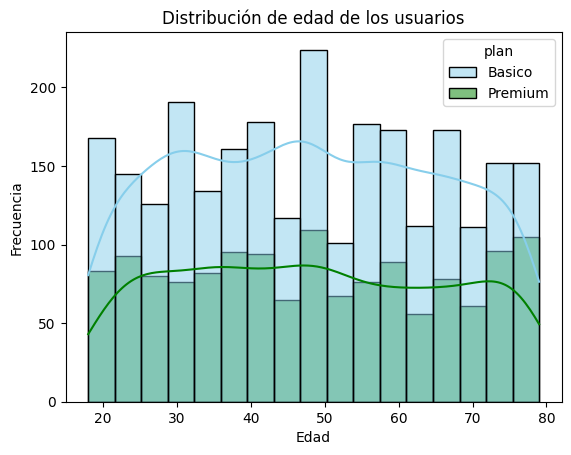

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data = user_profile, x = "age", hue='plan', palette=['skyblue','green'], kde=True)
plt.title('Distribución de edad de los usuarios')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- La distribución de la columna `age`, podemos evidenciar una gráfica que se ajusta a una gráfica normal, los datos de la población no muestran outliers, y vemos por el contrario datos ajustados y acomodados dentro de los rangos del histograma. Cabe resaltar que la mayoria de las obsercaciones muestran mayor población de usuarios que tienen adscrito el plan básico.

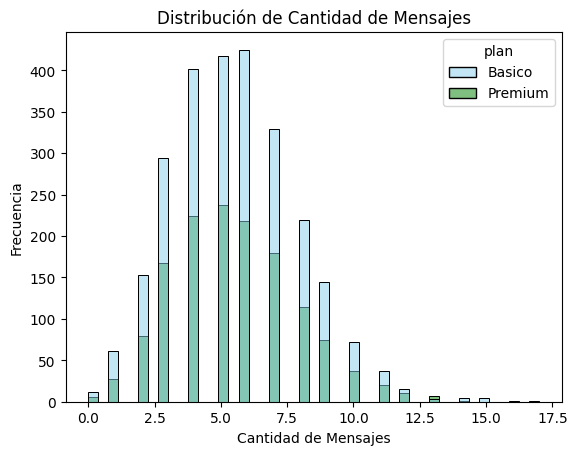

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data = user_profile, x = "cant_mensajes", hue='plan', palette=['skyblue','green'])
plt.title('Distribución de Cantidad de Mensajes')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Para la distribución de la gráfica de `cant_mensjes`, podemos ver un sesgo a la derecha ligero, ya que existen outliers pero estos son muy pocos, cabe resaltar que la mayoria de las obsercaciones muestran mayor población de usuarios que tienen adscrito el plan básico, pero los outliers se perciben con el tono asociado al plan premium, lo cual es de esperar que estos usuarios tengan un mayor uso del plan en mensajes.

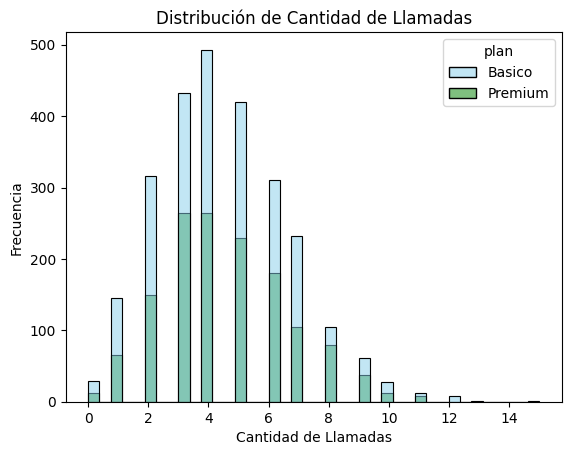

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data = user_profile, x = "cant_llamadas", hue='plan', palette=['skyblue','green'])
plt.title('Distribución de Cantidad de Llamadas')
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Para la distribución de la gráfica de `cant_llamadas`, podemos ver un sesgo a la derecha ligero, ya que existen outliers pero estos son muy pocos, cabe resaltar que la mayoria de las obsercaciones muestran mayor población de usuarios que tienen adscrito el plan básico, pero los outliers se perciben con el tono asociado al plan premium, lo cual es de esperar que estos usuarios tengan un mayor uso del plan en llamadas.

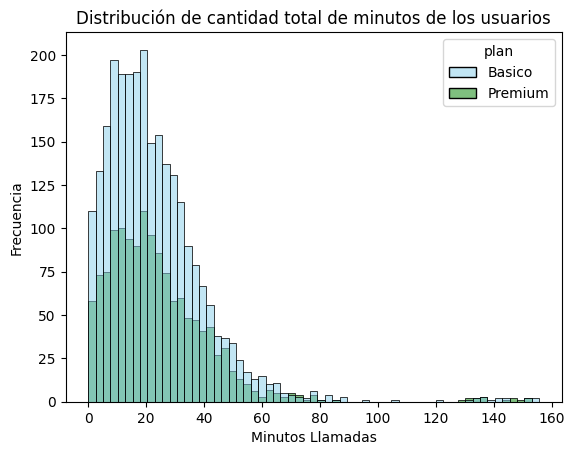

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data = user_profile, x = "cant_minutos_llamadas", hue='plan', palette=['skyblue','green'])
plt.title('Distribución de cantidad total de minutos de los usuarios')
plt.xlabel('Minutos Llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Para la distribución de la gráfica de `cant_minutos_llamadas`, podemos ver un sesgo a la derecha ligero, ya que existen outliers pero estos son muy pocos, cabe resaltar que la mayoria de las obsercaciones muestran mayor población de usuarios que tienen adscrito el plan básico, pero los outliers se perciben con el tono asociado al plan premium, lo cual es de esperar que estos usuarios tengan un mayor uso del plan en llamadas, además de mayor duración en las llamadas.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

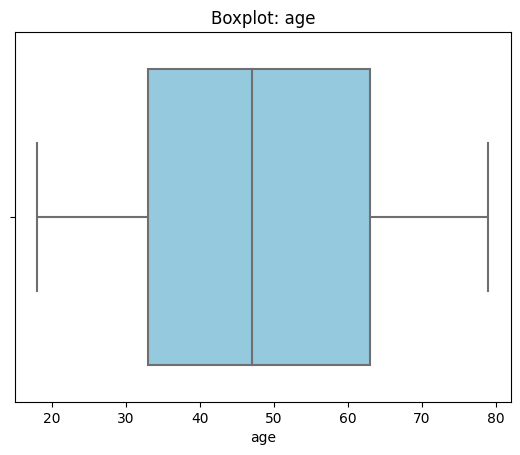

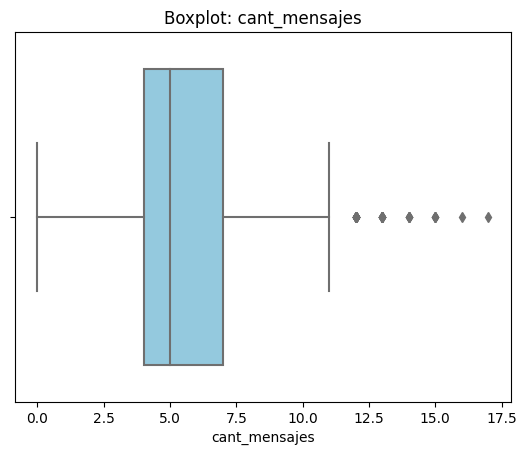

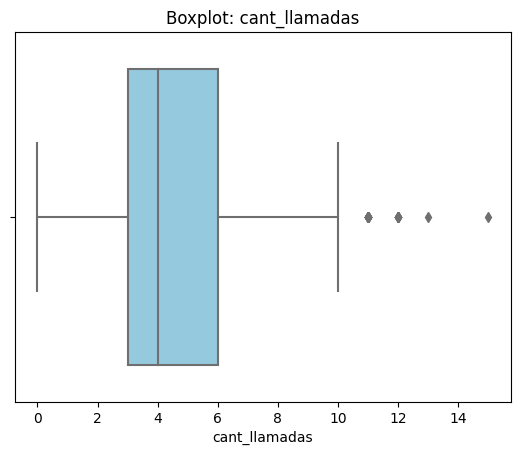

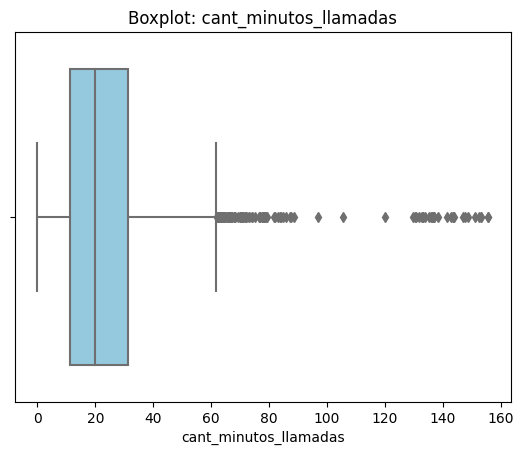

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamadas']

for col in columnas_numericas:
    sns.boxplot(x = user_profile[col], color = 'skyblue')
    plt.title(f'Boxplot: {col}')
    plt.show()
    

💡Insights: 
- Age: Se puede observar, tal y como se explico con el histrograma mostrado anteriormente, que diagrama de cajas y bigotes no muestra datos que distorsionen la media, y que los datos por el contrario se ajustan a una distribución normal; no presenta outliers
- cant_mensajes: Tiene una distribución levemente sesgada hacia la derecha con unos cuantos datos que distorsionan la media un poco, si hay outliers pero pocos
- cant_llamadas: Tiene una distribución levemente sesgada hacia la derecha con unos cuantos datos que distorsionan la media un poco, si hay outliers pero pocos
- cant_minutos_llamada: Tiene una gran cantidad de outliers que distorsionan la media, se puede ver en el diagrama de cajas y bigotes muchos valores que se salen de los extremos, mostrando un sesgo marcado a la derecha

In [35]:
# Calcular límites con el método IQR
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamadas']
columnas_limites ={}
for col in columnas_numericas:
    Q1=user_profile[col].quantile(0.25)
    Q2=user_profile[col].median()
    Q3=user_profile[col].quantile(0.75)
    IQR=Q3-Q1
    lower_limit = Q1-1.5*IQR
    upper_limit = Q3+1.5*IQR
    columnas_limites[col] =  {
        'Q1':Q1,
        'Q2':Q2,
        'Q3':Q3,
        'IQR':IQR,
        'lower_limit':lower_limit,
        'upper_limit':upper_limit
    }

print(columnas_limites)
print("El máximo de age es:",user_profile['age'].max())
print("El máximo de cant_mensajes es:",user_profile['cant_mensajes'].max())
print("El máximo de cant_llamadas es:",user_profile['cant_llamadas'].max())
print("El máximo de cant_minutos_llamadas es:",user_profile['cant_minutos_llamadas'].max())

{'age': {'Q1': 33.0, 'Q2': 47.0, 'Q3': 63.0, 'IQR': 30.0, 'lower_limit': -12.0, 'upper_limit': 108.0}, 'cant_mensajes': {'Q1': 4.0, 'Q2': 5.0, 'Q3': 7.0, 'IQR': 3.0, 'lower_limit': -0.5, 'upper_limit': 11.5}, 'cant_llamadas': {'Q1': 3.0, 'Q2': 4.0, 'Q3': 6.0, 'IQR': 3.0, 'lower_limit': -1.5, 'upper_limit': 10.5}, 'cant_minutos_llamadas': {'Q1': 11.12, 'Q2': 19.78, 'Q3': 31.415, 'IQR': 20.295, 'lower_limit': -19.322500000000005, 'upper_limit': 61.8575}}
El máximo de age es: 79.0
El máximo de cant_mensajes es: 17.0
El máximo de cant_llamadas es: 15.0
El máximo de cant_minutos_llamadas es: 155.69


In [38]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()
print("El máximo de cant_mensajes es:",user_profile['cant_mensajes'].max(),"El upper limit de cant_mensajes es:",columnas_limites["cant_mensajes"])
print("El máximo de cant_llamadas es:",user_profile['cant_llamadas'].max(),"El upper limit de cant_llamadas es:",columnas_limites["cant_llamadas"])
print("El máximo de cant_minutos_llamadas es:",user_profile['cant_minutos_llamadas'].max(),"El upper limit de cant_minutos_llamadas es:",columnas_limites["cant_minutos_llamadas"])

El máximo de cant_mensajes es: 17.0 El upper limit de cant_mensajes es: {'Q1': 4.0, 'Q2': 5.0, 'Q3': 7.0, 'IQR': 3.0, 'lower_limit': -0.5, 'upper_limit': 11.5}
El máximo de cant_llamadas es: 15.0 El upper limit de cant_llamadas es: {'Q1': 3.0, 'Q2': 4.0, 'Q3': 6.0, 'IQR': 3.0, 'lower_limit': -1.5, 'upper_limit': 10.5}
El máximo de cant_minutos_llamadas es: 155.69 El upper limit de cant_minutos_llamadas es: {'Q1': 11.12, 'Q2': 19.78, 'Q3': 31.415, 'IQR': 20.295, 'lower_limit': -19.322500000000005, 'upper_limit': 61.8575}


💡Insights: 
- cant_mensajes: Se puede observar que a través de la metodología IQR, que el upper_limit (11.5) de la columna es menor que el valor maximo (17), por lo tanto existen outliers que afectan un poco el valor de la media, al no estar muy alejados del máximo es posible mantener los valores o decidir si se aplica el método de winzorización para estabilizar los datos
- cant_llamadas: Se puede observar que a través de la metodología IQR, que el upper_limit (10.5) de la columna es menor que el valor maximo (15), por lo tanto existen outliers que afectan un poco el valor de la media, al no estar muy alejados del máximo es posible mantener los valores o decidir si se aplica el método de winzorización para estabilizar los datos
- cant_minutos_llamada: Se puede observar que a través de la metodología IQR, que el upper_limit (61.8575), es mucho menor que el valor máximo (155.69) de la población de datos de la columna, al ser ver en el boxplot una cantidad de outliers importante, aquí toca aplicar el método de winzorización para estabilizar la muestra de datos.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
def classify_grupo_uso (row):
    num_llamadas = row['cant_llamadas']
    num_mensajes = row['cant_mensajes']
    
#Generación segmento grupo de uso:
    if num_llamadas >= 10 and num_mensajes >= 10: #Alto uso
        return 'Alto uso'
    elif num_llamadas >= 5 and num_mensajes >= 5: # Medio uso
        return 'Medio uso'
    else: #Bajo uso
        return 'Bajo uso'

#Aplicar la función y ver los cambios
user_profile['grupo_uso'] = user_profile.apply(classify_grupo_uso, axis=1)

In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,cant_mensajes,cant_llamadas,cant_minutos_llamadas,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,7.0,3.0,23.70,Bajo uso
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619,Basico,NaN,2022,5.0,10.0,33.18,Medio uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,5.0,2.0,10.74,Bajo uso
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022,11.0,3.0,8.99,Bajo uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [41]:
# Crear columna grupo_edad
def classify_grupo_edad (row):
    edad = row['age']

#Generación de segmento grupo_edad:
    if edad >= 60: #Condición adulto mayor
        return 'Adulto Mayor'
    elif edad >=30: #Condición adulto 
        return 'Adulto'
    else: #Condición joven
        return 'Joven'
#Aplicar la función y verificar los cambios
user_profile['grupo_edad'] = user_profile.apply(classify_grupo_edad, axis=1)


In [42]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,cant_mensajes,cant_llamadas,cant_minutos_llamadas,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,7.0,3.0,23.70,Bajo uso,Adulto
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619,Basico,NaN,2022,5.0,10.0,33.18,Medio uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,5.0,2.0,10.74,Bajo uso,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022,11.0,3.0,8.99,Bajo uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

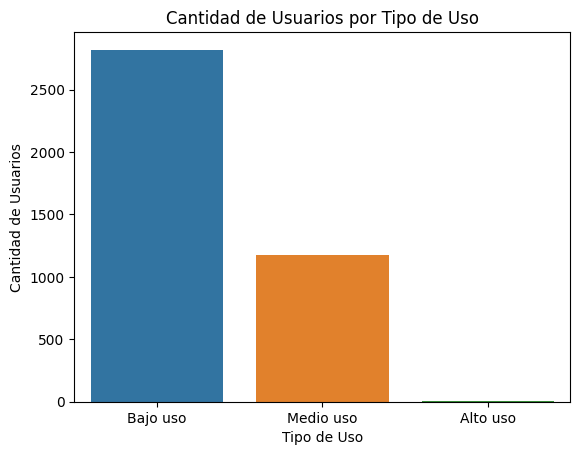

In [44]:
# Visualización de los segmentos por uso

sns.countplot(data = user_profile, x='grupo_uso')
plt.title('Cantidad de Usuarios por Tipo de Uso')
plt.xlabel('Tipo de Uso')
plt.ylabel('Cantidad de Usuarios')
plt.show()


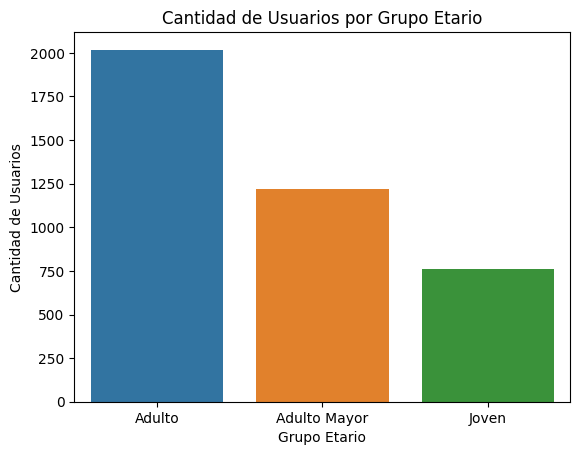

In [45]:
# Visualización de los segmentos por edad
sns.countplot(data = user_profile, x='grupo_edad')
plt.title('Cantidad de Usuarios por Grupo Etario')
plt.xlabel('Grupo Etario')
plt.ylabel('Cantidad de Usuarios')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Se encontró en el dataset users, la columna `age` la cual se encontró un sentinel con el valor de -999, lo cual es un valor no lógico para la edad, de estas se encontraron 55 observaciones con ese sentinel, se determino imputar la mediana en dicha columna, reemplazando dichos sentiels y de esa forma poder garantizar estabilidad entre los datos de la variable; por otra parte dentro del dataset usage, en la columna `city`, se encontrarón observaciones con signo `?`, lo cual es otro sentinel al cual se le dió tratamiento manejando los valores como NA. 
- En la columna `reg_date` se encontraron fechas futuras, es decir, teniendo en cuenta que el dataset solo maneja valores hasta 2024, observaciones con años posteriores evidencia valores que no son lógicos para el dataset, por ende se toma la determinación de dejar estos valores como NA

🔍 **Segmentos por Edad**
- Se desarrollan segmentaciones para clasificar por edades a los usuarios, en aras de poder encontrar patrones o hallazgos estádisticos con base a grupos etarios denominados como "Adulto", "Adulto mayor", "joven"; dentro de estos grupos se pudo encontrar que la mayor concentración de usarios son "Adultos" los cuales tienen aproximadamente 2000 usuarios clasificados en este grupo, seguido de "Adulto Mayor" los cuales tienen cerca de 1250 usuarios, finalizando con la menor cantidad de usarios clasificados como "Joven" los cuales llegan a 750 usuarios

📊 **Segmentos por Nivel de Uso**
- Se desarrollan segmentaciones para clasificar por tipo de uso a los usuarios, en aras de poder encontrar patrones o hallazgos estadisticos con base a los tipos de uso o consumo entre los usuarios, se encuentra que la mayor concentración de usuarios (más de 2500 usuarios) tiene un nivel de uso bajo, seguido por un nivel de uso medio el cual está cercano a los 1250 usuarios, a su vez se encontró un nivel de uso alto, casi nulo, los cuales son los usuarios que mostraron mayor cantidad de minutos en llamadas, o mayor duración en las llamadas, los cuales son muy pocos, pero marcan un impacto en el consumo

➡️ Esto sugiere que se debería profundizar el análisis realizando conbinaciones de los segmentos realizados, para determinar que cantidad de usuarios son adultos y consumen bajo, los cuales se esperaría sean la mayoría, a su vez cuales serían la población de adultos que tienen consumo medio o consumo alto, y lo mismo con los diferentes grupos etarios, se esperaría que la totalidad de los usuarios jovenes, tienen plan básico, y uso bajo.

💡 **Recomendaciones**
- Una vez encontradas las diferentes conbinaciones entre segmentos, podriamos identificar un grupo etario, al cual sea más conveniente implementar una diferente campaña para aumentar bien sea o el tipo de plan, o el uso, un grupo potencial para generar una buena campaña con un plan mejorado, respecto al básico o premium, y así mover ese grupo etario, a un mayor consumo, o mejor plan de telefonía.
 

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`